# Aragonite saturation state projections

Decadal projections of the surface ocean carbonate system on a 1° grid (median of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html)), mapped over the whole Pacific window and averaged over the four ocean regions (North Pacific Subtropical Gyre, Equatorial Upwelling, Western Equatorial Pacific and South Pacific Subtropical Gyre). The decadal series of the median product are shown in each region; the fields of the 14 individual Earth system models give the spread across models at the global warming levels (box plots).

```{glue:figure} aragonite_fig
:scale: 60%
:align: center
```

**Figure. Change in aragonite saturation state between 2020 and 2100 over the Pacific**, one panel per scenario (dashed boxes: ocean regions).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Aragonite saturation state by decade

**Aragonite saturation state: change 2020–2100 of the median product (Ω), by ocean region**

scenario,SSP126,SSP245,SSP370,SSP585
region,,,,
North Pacific Subtropical Gyre,-0.1220,-0.6366,-1.1690,-1.5474
Equatorial Upwelling,-0.1079,-0.5442,-0.9794,-1.3541
Western Equatorial Pacific,-0.1907,-0.6842,-1.2274,-1.6531
South Pacific Subtropical Gyre,-0.1498,-0.6392,-1.1804,-1.5655


**Aragonite saturation state by decade in the ocean regions (median product, Ω)**

scenario                             ssp126  ssp245  ssp370  ssp585
region                         Year                                
Equatorial Upwelling           2020  3.4206  3.4163  3.4164  3.4185
                               2030  3.3632  3.3375  3.3413  3.3325
                               2040  3.2640  3.2232  3.1830  3.1809
                               2050  3.2151  3.1304  3.0510  3.0015
                               2060  3.2049  3.0487  2.9380  2.8345
                               2070  3.1924  2.9580  2.7851  2.6210
                               2080  3.2075  2.8962  2.6529  2.4021
                               2090  3.2091  2.8707  2.5381  2.2118
                               2100  3.3127  2.8722  2.4370  2.0644
North Pacific Subtropical Gyre 2020  3.4993  3.5027  3.4952  3.4965
                               2030  3.4060  3.3889  3.3624  3.3540
                               2040  3.3107  3.2550  3.1857  3.1744
                               2050  3.2628  3.1477  3.0355  2.9779
                               2060  3.2477  3.0498  2.8863  2.7626
                               2070  3.2403  2.9646  2.7258  2.5401
                               2080  3.2754  2.9118  2.5933  2.3181
                               2090  3.2988  2.8596  2.4384  2.0973
                               2100  3.3773  2.8661  2.3262  1.9491
South Pacific Subtropical Gyre 2020  3.4905  3.4805  3.4925  3.4871
                               2030  3.3693  3.3477  3.3269  3.3279
                               2040  3.2985  3.2381  3.1819  3.1533
                               2050  3.2489  3.1221  3.0197  2.9584
                               2060  3.2285  3.0142  2.8582  2.7344
                               2070  3.2349  2.9404  2.7245  2.5033
                               2080  3.2399  2.8753  2.5725  2.2874
                               2090  3.2954  2.8544  2.4568  2.0979
                               2100  3.3406  2.8413  2.3121  1.9216
Western Equatorial Pacific     2020  3.7288  3.7369  3.7234  3.7350
                               2030  3.6288  3.6224  3.5893  3.6113
                               2040  3.5297  3.4795  3.4225  3.4107
                               2050  3.4857  3.3752  3.2654  3.2104
                               2060  3.4605  3.2755  3.1140  2.9857
                               2070  3.4428  3.1706  2.9329  2.7301
                               2080  3.4691  3.1026  2.8018  2.5136
                               2090  3.5154  3.0784  2.6530  2.2921
                               2100  3.5380  3.0527  2.4960  2.0819

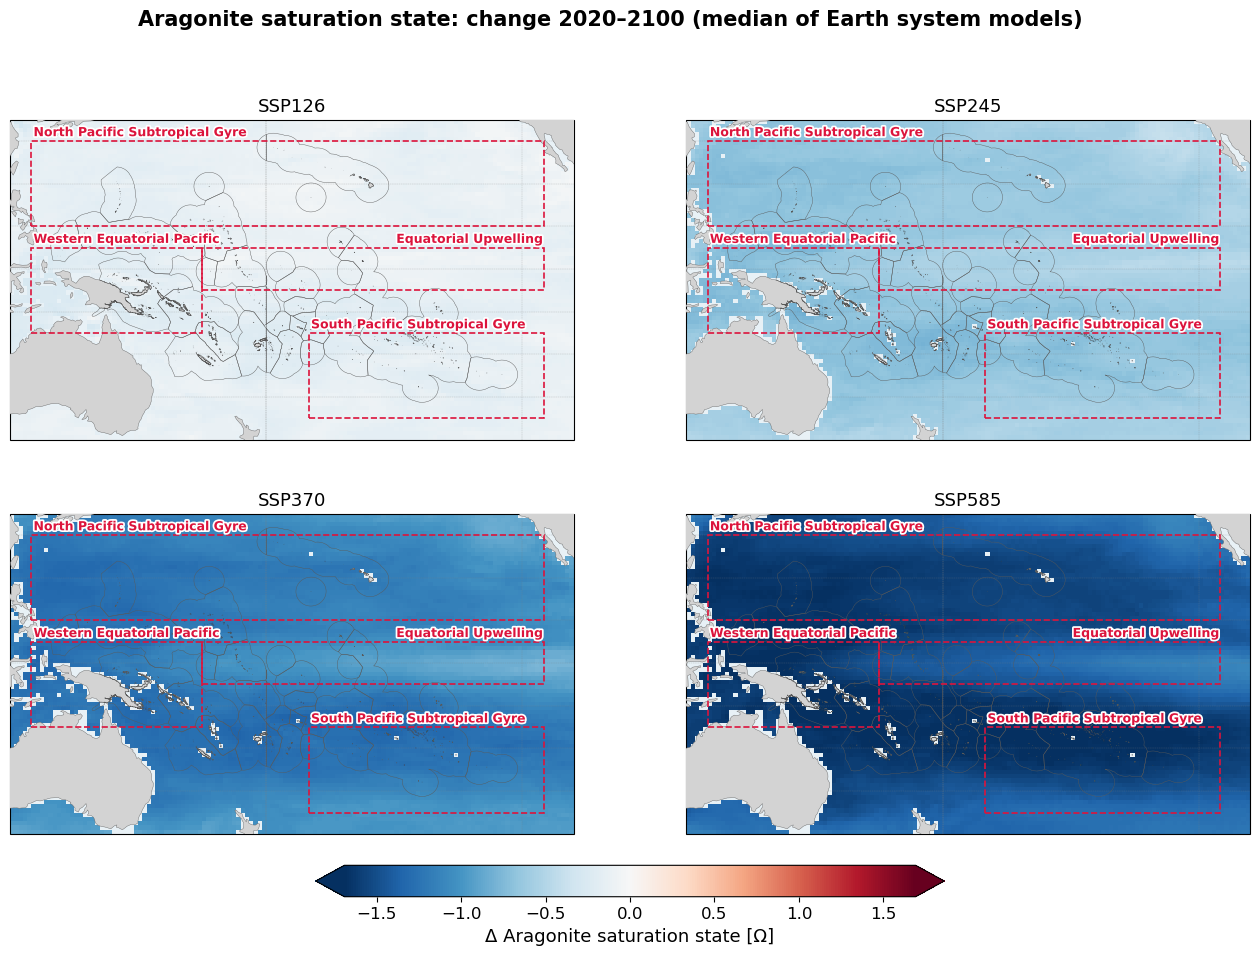

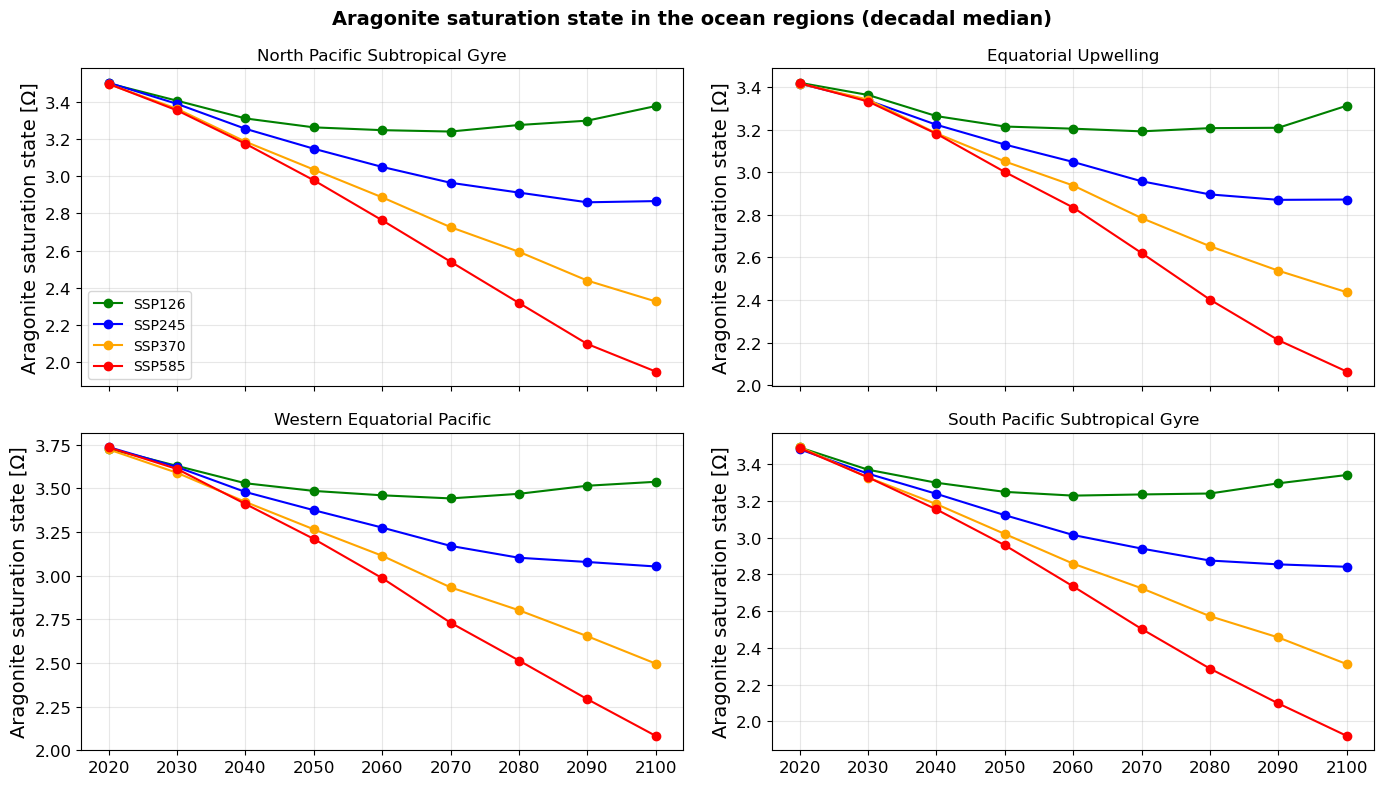

In [4]:
ds_ocads = reg.extract_ocads_regional("aragonite", eez, ssp_scenarios)
figs, tables = reg.ocads_report(ds_ocads, "aragonite", "Aragonite saturation state", "Ω", eez, ssp_scenarios, fig_dir, tables_dir, cmap="RdBu_r")
glue("aragonite_fig", figs["change"], display=False)
reg.show_tables(tables)


## Aragonite saturation state at global warming levels

Every Earth system model of Jiang et al. (2023) (`bio/nc/ESMs`) averaged over the four ocean regions. The decadal values are interpolated linearly to annual values, so the warming-level years of the national projections can be used, and expressed as the change relative to each model's 2020–2030 mean. Box plots show the spread across models in each region; not every model ran every scenario (SSP1-2.6 and SSP3-7.0: 11 models, SSP2-4.5: 13, SSP5-8.5: 14).


**Aragonite saturation state: linear trend 2020–2100 of the multi-model median (Ω per decade), by ocean region**

,SSP126,SSP245,SSP370,SSP585
North Pacific Subtropical Gyre,-0.01679,-0.08403,-0.14791,-0.20393
Equatorial Upwelling,-0.01732,-0.07478,-0.12839,-0.18150
Western Equatorial Pacific,-0.02121,-0.09053,-0.15341,-0.21370
South Pacific Subtropical Gyre,-0.01413,-0.08103,-0.14594,-0.20311


**Δ Aragonite saturation state vs 2020–2030 at the global warming levels (Ω): spread across Earth system models by ocean region**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,11,-0.0669,-0.0772,-0.0564,-0.0794,-0.0542
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,13,-0.0577,-0.0782,-0.0447,-0.1023,-0.0438
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,11,-0.7473,-0.7919,-0.7245,-0.8334,-0.7169
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,14,-0.0304,-0.0382,-0.0245,-0.0469,-0.0216
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,14,-0.2696,-0.2968,-0.2365,-0.3148,-0.2089
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,14,-0.5021,-0.5458,-0.4835,-0.6041,-0.4750


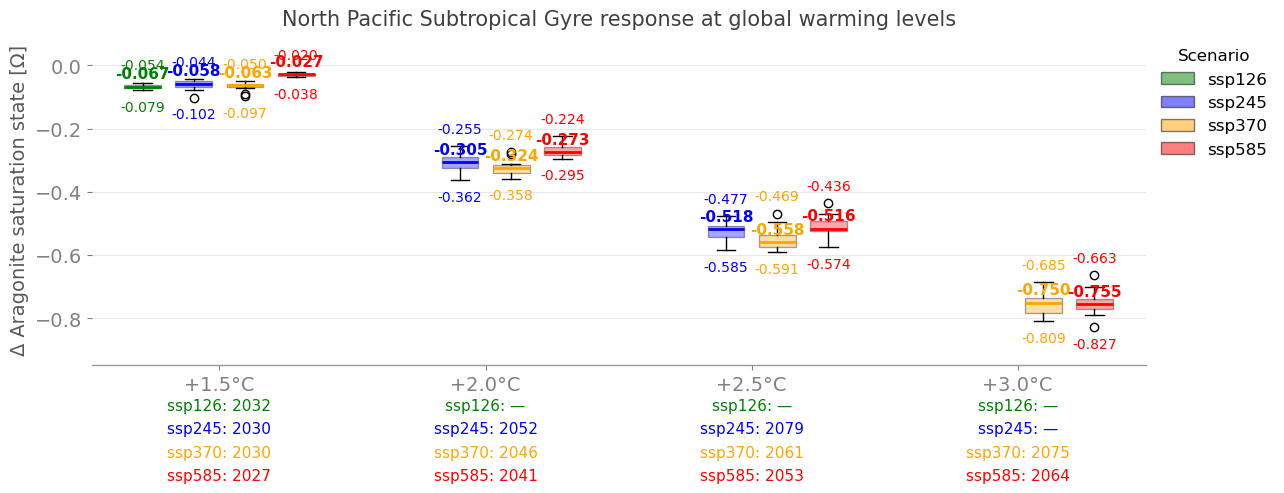

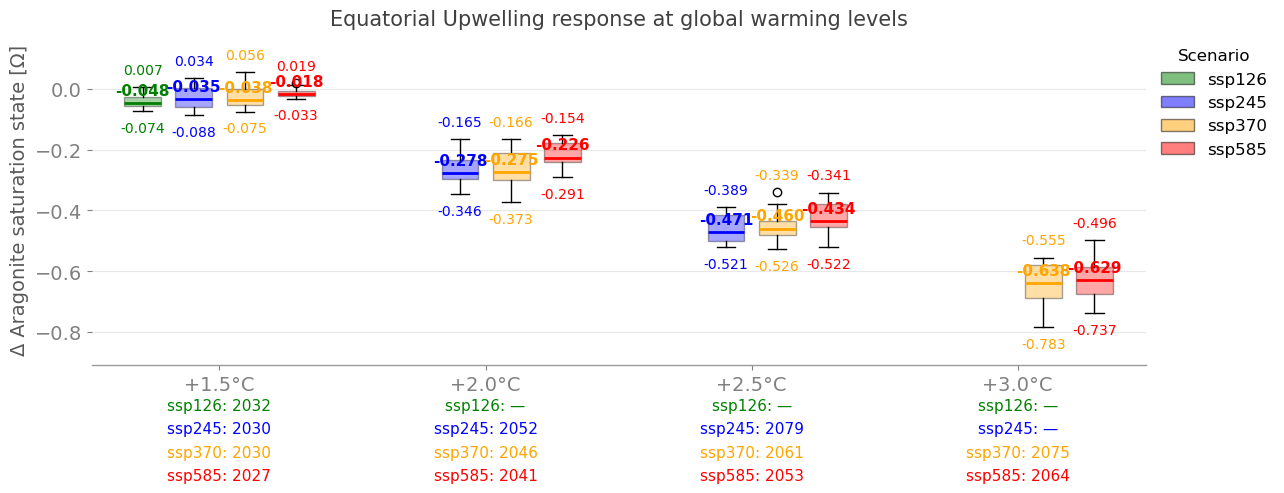

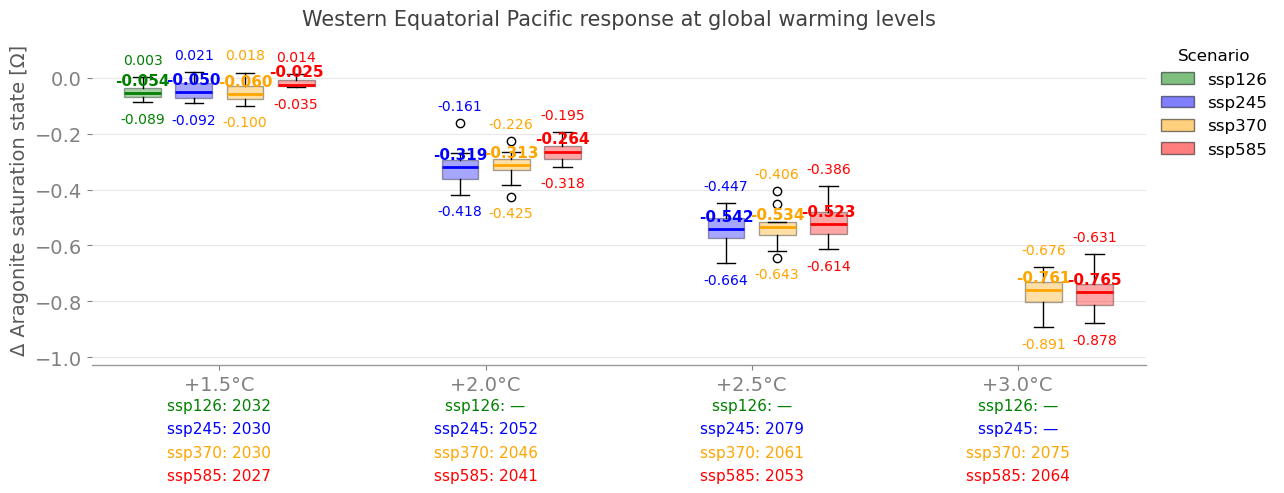

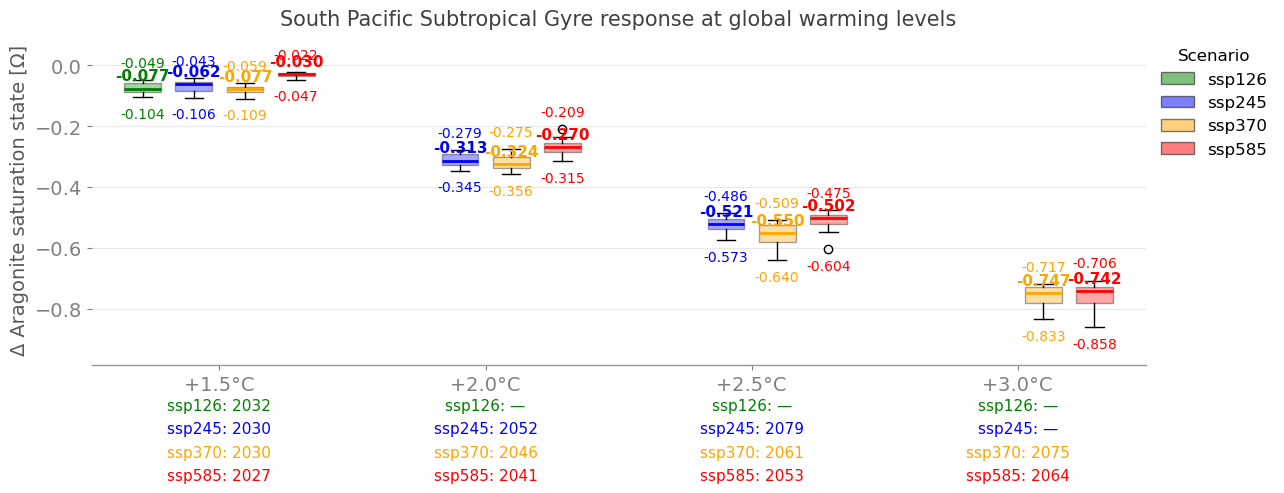

In [5]:
ds_models = reg.extract_ocads_models_regional("aragonite", eez, ssp_scenarios)
figs_gwl, tables_gwl = reg.ocads_model_analysis(ds_models, "aragonite", "Aragonite saturation state", "Ω", scenario_info, ssp_scenarios,
                                                fig_dir, tables_dir)
reg.show_tables(tables_gwl)
